In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import normalized_mutual_info_score as nmi
from sklearn.metrics import adjusted_rand_score as ari
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [2]:
digits = load_digits()

X = digits.data
print(X.shape)

(1797, 64)


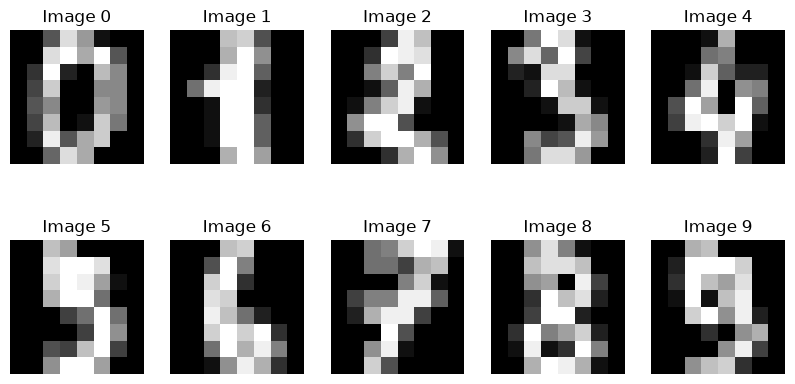

In [4]:
plt.figure(figsize=(10 , 5))

for i in range(10):
    plt.subplot(2 , 5 , i+1)
    plt.imshow(digits.images[i] , cmap='gray')
    plt.title(f'Image {i}')
    plt.axis('off')
    

plt.show()

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)

(1797, 64)


In [6]:
dataframe = pd.DataFrame(X)

In [7]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 1797 entries, 0 to 1796
Data columns (total 64 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       1797 non-null   float64
 1   1       1797 non-null   float64
 2   2       1797 non-null   float64
 3   3       1797 non-null   float64
 4   4       1797 non-null   float64
 5   5       1797 non-null   float64
 6   6       1797 non-null   float64
 7   7       1797 non-null   float64
 8   8       1797 non-null   float64
 9   9       1797 non-null   float64
 10  10      1797 non-null   float64
 11  11      1797 non-null   float64
 12  12      1797 non-null   float64
 13  13      1797 non-null   float64
 14  14      1797 non-null   float64
 15  15      1797 non-null   float64
 16  16      1797 non-null   float64
 17  17      1797 non-null   float64
 18  18      1797 non-null   float64
 19  19      1797 non-null   float64
 20  20      1797 non-null   float64
 21  21      1797 non-null   float64
 22  22      179

In [8]:
dataframe.head()

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


In [9]:
dataframe.tail()

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0
1796,0.0,0.0,10.0,14.0,8.0,1.0,0.0,0.0,0.0,2.0,...,8.0,0.0,0.0,1.0,8.0,12.0,14.0,12.0,1.0,0.0


In [10]:
dataframe.describe()

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
count,1797.0,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,...,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000
mean,0.0,0.303840,5.204786,11.835838,11.848080,5.781859,1.362270,0.129661,0.005565,1.993879,...,3.725097,0.206455,0.000556,0.279354,5.557596,12.089037,11.809126,6.764051,2.067891,0.364496
std,0.0,0.907192,4.754826,4.248842,4.287388,5.666418,3.325775,1.037383,0.094222,3.196160,...,4.919406,0.984401,0.023590,0.934302,5.103019,4.374694,4.933947,5.900623,4.090548,1.860122
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,11.000000,10.000000,0.000000,0.000000,0.000000
50%,0.0,0.000000,4.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,4.000000,13.000000,14.000000,6.000000,0.000000,0.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,11.000000,0.000000,0.000000,0.000000,3.000000,...,7.000000,0.000000,0.000000,0.000000,10.000000,16.000000,16.000000,12.000000,2.000000,0.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,15.000000,2.000000,16.000000,...,16.000000,13.000000,1.000000,9.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000


In [13]:
dataframe.isnull().sum().sum()

np.int64(0)

In [14]:
pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X)
print(X_pca.shape)

(1797, 21)


In [15]:
pca.explained_variance_ratio_

array([0.14890594, 0.13618771, 0.11794594, 0.08409979, 0.05782415,
       0.0491691 , 0.04315987, 0.03661373, 0.03353248, 0.03078806,
       0.02372341, 0.02272697, 0.01821863, 0.01773855, 0.01467101,
       0.01409716, 0.01318589, 0.01248138, 0.01017718, 0.00905617,
       0.00889538])

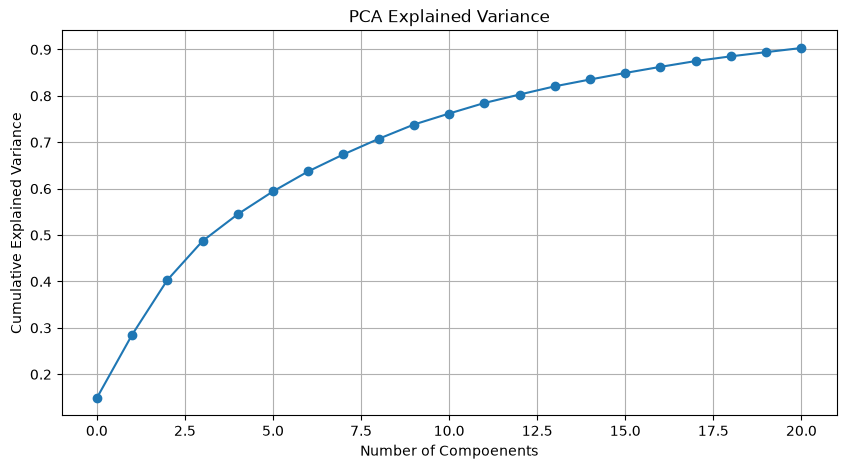

In [16]:
plt.figure(figsize=(10 , 5))

plt.plot(np.cumsum(pca.explained_variance_ratio_) , marker='o')


plt.title('PCA Explained Variance')
plt.xlabel('Number of Compoenents')
plt.ylabel('Cumulative Explained Variance')
plt.grid()
plt.show()

In [18]:
inertias = []

for k in range(2 , 16):
    kmeans = KMeans(n_clusters=k , init='k-means++' , n_init=10  , random_state=42)
    kmeans.fit(X_pca)
    inertias.append(kmeans.inertia_)

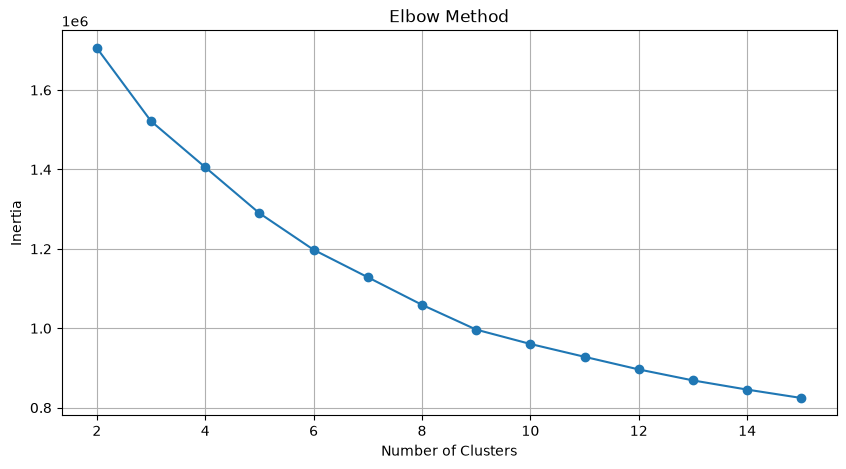

In [22]:
plt.figure(figsize=(10 , 5))

plt.plot(range(2 , 16) , inertias , marker='o')


plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.grid()
plt.show()

In [23]:
silhouette_scores = []

for k in range(2 , 16):
    kmeans = KMeans(n_clusters=k , init='k-means++' , n_init=10  , random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca , labels)
    silhouette_scores.append(score)

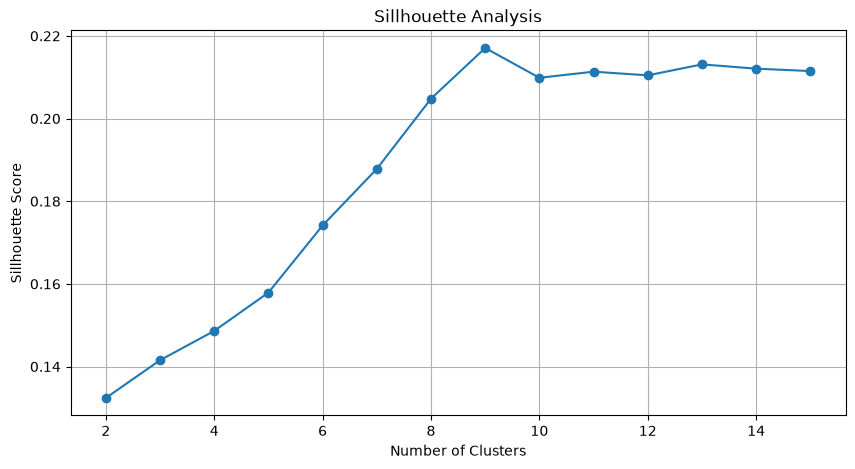

In [24]:
plt.figure(figsize=(10 , 5))

plt.plot(range(2 , 16) , silhouette_scores , marker='o')


plt.title('Sillhouette Analysis')
plt.xlabel('Number of Clusters')
plt.ylabel('Sillhouette Score')
plt.grid()
plt.show()

In [25]:
kmeans_original = KMeans(n_clusters=10 , init='k-means++' , n_init=10 , random_state=42)
labels = kmeans_original.fit_predict(X_pca)
print(labels[:20])

[8 0 0 9 6 2 4 3 0 2 8 7 5 9 6 1 4 3 0 2]


In [26]:
y_true = digits.target

score_original = silhouette_score(X_pca , labels)
nmi = nmi(y_true , labels)
ari = ari(y_true , labels)

In [28]:
print('Score : ',score_original)
print('NMI:',nmi)
print('ARI:',ari)

Score :  0.209866546464678
NMI: 0.746306534806364
ARI: 0.6727510466209679


In [33]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X)
print(X_2d.shape)

(1797, 2)


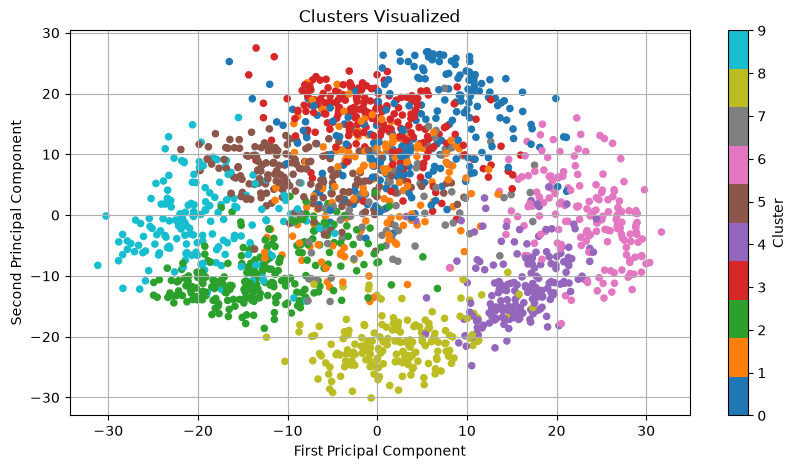

In [ ]:
plt.figure(figsize=(10 , 5))
plt.scatter(X_2d[: , 0] , X_2d[: , 1] , c = labels , cmap='tab10' , s=20)


plt.title('Clusters Visualized')
plt.xlabel('First Pricipal Component')
plt.ylabel('Second Principal Component')
plt.colorbar(label='Cluster')
plt.grid()
plt.show()

In [ ]:
centers_original = pca.inverse_transform(kmeans_original.cluster_centers_)

In [39]:
centers_images = centers_original.reshape(10 , 8 , 8)

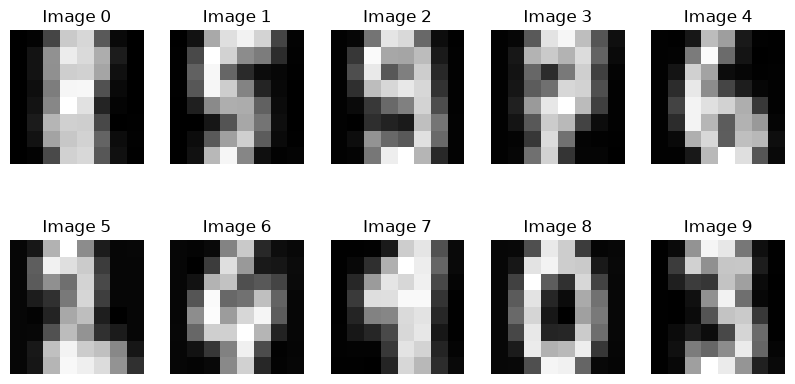

In [42]:
plt.figure(figsize=(10 , 5))

for i in range(10):
    plt.subplot(2 , 5 , i+1)
    plt.imshow(centers_images[i] , cmap='gray')
    plt.title(f'Image {i}')
    plt.axis('off')

plt.show()